# PBI 7 — Fraud Detection with XGBoost
**Individual contribution: Isabelle Poh | Group 2 | ST1519 Agile MLOps CA1**

## 1. Business objective
Develop a model to identify potentially fraudulent SP-buy orders for Trust & Safety review. A flagged order is a candidate for investigation, not confirmed fraud or an automatic cancellation. The two versions use the same nine shared predictors, chronological evaluation procedure and review threshold of 0.5. V2 addresses the missed fraud observed in V1 by weighting the positive class.

## 2. Setup and reproducibility
Run this notebook from the project root or `notebooks/` using the project's `.venv` Python kernel. It reuses `src.features`, the shared historical loader and the models produced by `src.models.train_xgboost`. No AWS connection is needed until the optional remote verification section.

If local reports or models are missing, run these commands from the repository root using the original historical CSVs. The evaluation commands below omit MLflow logging to avoid duplicate cloud runs. Existing reports with MLflow IDs should be retained if available.

```powershell
python -m src.models.train_xgboost --version v1 --split validation --threshold 0.5
python -m src.models.train_xgboost --version v2 --split validation --threshold 0.5
python -m src.models.train_xgboost --version v1 --split evaluation --threshold 0.5
python -m src.models.train_xgboost --version v2 --split evaluation --threshold 0.5
```

In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import load
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    average_precision_score, roc_auc_score,
)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "features.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside AMLOP_CA1_Group2.")
sys.path.insert(0, str(ROOT))

from src.features import chronological_split
from src.models.train_random_forest import load_historical_data, decision_metrics

DATA_DIR = Path(os.environ.get("SPBUY_DATA_DIR") or ROOT / "data" / "raw")
REPORT_DIR = ROOT / "reports" / "pbi7-xgboost"
THRESHOLD = 0.5
VERSIONS = ("v1", "v2")
SPLITS = ("validation", "evaluation")

reports = {}
for split in SPLITS:
    for version in VERSIONS:
        path = REPORT_DIR / f"{split}-{version}.json"
        if not path.is_file():
            raise FileNotFoundError(f"Missing {path}. Run the training command above.")
        reports[split, version] = json.loads(path.read_text(encoding="utf-8"))
        assert reports[split, version]["threshold"] == THRESHOLD
        assert reports[split, version]["scored_split"] == split
print("Project root:", ROOT)
print("Loaded all four experiment reports.")

Project root: c:\Users\isabe\OneDrive\Documents\GitHub\AMLOP_CA1_Group2
Loaded all four experiment reports.


## 3. Shared data preparation and class imbalance
The shared feature engineering excludes identifiers, refund amounts and customer snapshots whose availability at order time cannot be established. Only orders with a valid binary fraud label, matched customer and valid order date are eligible. The nine inputs describe order amount, item count, value per item, customer tenure, country, collection type, payment method, weekday and month.

The fitted pipeline handles missing values and categorical encoding using training data only. The XGBoost implementation uses dense transformed data so that zero values are not interpreted as absent sparse entries.

Eligible orders: 949,872
Fraud rate: 10.99%


,feature,dtype
0,order_value,float64
1,num_items_ordered,float64
2,value_per_item,float64
3,customer_tenure_days,float64
4,country_code,object
5,collect_type,object
6,payment_method,object
7,order_weekday,object
8,order_month,object


,orders,percentage
Non-fraud,845450,89.006729
Fraud,104422,10.993271


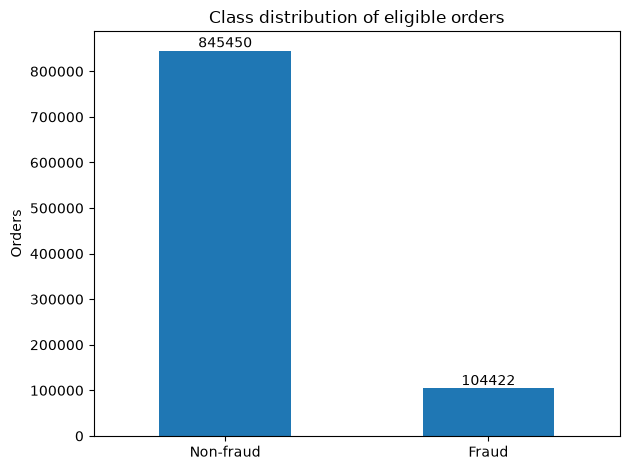

In [2]:
X, y, metadata, audit = load_historical_data(DATA_DIR)
print(f"Eligible orders: {len(X):,}")
print(f"Fraud rate: {y.mean():.2%}")
display(pd.DataFrame({"feature": X.columns, "dtype": X.dtypes.astype(str).values}))
counts = y.value_counts().reindex([0, 1], fill_value=0)
counts.index = ["Non-fraud", "Fraud"]
display(pd.DataFrame({"orders": counts, "percentage": counts / len(y) * 100}))
ax = counts.plot.bar(rot=0, title="Class distribution of eligible orders")
ax.set_ylabel("Orders")
ax.bar_label(ax.containers[0], fmt="%d")
plt.tight_layout()
plt.show()

## 4. Chronological split
The newest approximately 20% of orders are reserved for final evaluation. The older development period is split again into training and validation. Entire dates remain in one partition. V1 and V2 are compared on the same validation rows during development and are then refitted on the full development period for final evaluation. No final evaluation rows are used for fitting or choosing the weighting strategy.

In [3]:
development, evaluation = chronological_split(metadata)
training, validation = chronological_split(metadata.loc[development])
assert set(training).isdisjoint(validation)
assert set(development).isdisjoint(evaluation)
assert metadata.loc[training, "order_date"].max() < metadata.loc[validation, "order_date"].min()
assert metadata.loc[development, "order_date"].max() < metadata.loc[evaluation, "order_date"].min()

split_rows = []
for name, rows in [("Training", training), ("Validation", validation),
                   ("Final training", development), ("Final evaluation", evaluation)]:
    dates = metadata.loc[rows, "order_date"]
    split_rows.append({"split": name, "start": dates.min().date(),
                       "end": dates.max().date(), "orders": len(rows),
                       "fraud_orders": int(y.loc[rows].sum()),
                       "fraud_rate": y.loc[rows].mean()})
display(pd.DataFrame(split_rows))
for split, fit_rows, scored_rows in [("validation", training, validation),
                                     ("evaluation", development, evaluation)]:
    for version in VERSIONS:
        report = reports[split, version]
        for key, rows in [("train", fit_rows), ("scored", scored_rows)]:
            dates = metadata.loc[rows, "order_date"]
            expected = (len(rows), int(y.loc[rows].sum()),
                        dates.min().date().isoformat(), dates.max().date().isoformat())
            actual = tuple(report[key][field] for field in ["rows", "fraud_rows", "start", "end"])
            assert actual == expected, f"Saved report does not match current data: {split}, {version}, {key}"
print("Saved reports match current split counts and date ranges.")

,split,start,end,orders,fraud_orders,fraud_rate
0,Training,2022-11-12,2023-03-04,606483,60484,0.099729
1,Validation,2023-03-05,2023-04-03,151542,19883,0.131205
2,Final training,2022-11-12,2023-04-03,758025,80367,0.106022
3,Final evaluation,2023-04-04,2023-05-11,191847,24055,0.125386


Saved reports match current split counts and date ranges.


## 5. V1 baseline and validation results
XGBoost builds an ensemble of boosted decision trees. The baseline uses 100 trees, maximum depth 4, learning rate 0.1 and histogram-based training. Fraud and non-fraud examples are given equal per-example weight (`scale_pos_weight=1`).

The original validation run achieved 69.63% precision but only 21.05% recall, missing 15,698 of 19,883 fraudulent orders. ROC-AUC was 0.8510, indicating useful ranking performance even though the 0.5 decision threshold missed most fraud. This is the motivation for V2.

In [4]:
def metrics_table(split):
    return pd.DataFrame({version.upper(): reports[split, version]["metrics"]
                         for version in VERSIONS})

keys = ["accuracy", "fraud_precision", "fraud_recall", "fraud_f1",
        "average_precision", "roc_auc", "true_negatives", "false_positives",
        "false_negatives", "true_positives", "fit_seconds", "model_size_mb"]
print("V1 validation metrics")
display(metrics_table("validation").loc[keys, ["V1"]].round(4))

V1 validation metrics


,V1
accuracy,0.8844
fraud_precision,0.6963
fraud_recall,0.2105
fraud_f1,0.3233
average_precision,0.5263
roc_auc,0.8510
true_negatives,129834.0000
false_positives,1825.0000
false_negatives,15698.0000
true_positives,4185.0000


## 6. V2 improvement: class weighting
The training dataset contains substantially more non-fraudulent than fraudulent orders. To reduce missed fraud, V2 increases the weight of positive examples using the ratio of non-fraud to fraud orders in the training split. All other model hyperparameters are kept unchanged, isolating the effect of weighting. The ratio is recalculated when training data changes, rather than being hardcoded.

The review threshold remains 0.5 for both versions. Class weighting changes the model scores; the scores should not be assumed to be calibrated probabilities of fraud.

In [5]:
weights = []
for name, rows in [("validation", training), ("evaluation", development)]:
    target = y.loc[rows]
    ratio = int((target == 0).sum()) / int((target == 1).sum())
    logged = reports[name, "v2"]["parameters"]["scale_pos_weight"]
    assert np.isclose(ratio, logged)
    weights.append({"split": name, "negative": int((target == 0).sum()),
                    "positive": int((target == 1).sum()), "weight": ratio})
display(pd.DataFrame(weights))
params = pd.DataFrame({v.upper(): reports["validation", v]["parameters"] for v in VERSIONS})
display(params)

,split,negative,positive,weight
0,validation,545999,60484,9.027164
1,evaluation,677658,80367,8.432043


,V1,V2
objective,binary:logistic,binary:logistic
n_estimators,100,100
max_depth,4,4
learning_rate,0.1,0.1
scale_pos_weight,1.0,9.027164
subsample,1.0,1.0
colsample_bytree,1.0,1.0
tree_method,hist,hist
eval_metric,logloss,logloss
random_state,42,42


## 7. Validation comparison
In the original validation runs, recall rose from 21.05% to 79.30% and F1 from 32.33% to 51.15%, while precision fell to 37.75%. False negatives fell from 15,698 to 4,116, at the cost of more false positives (1,825 to 26,002). Average precision declined slightly and ROC-AUC stayed almost unchanged. The improvement is therefore mainly in classification decisions at the common threshold, not better overall ranking. Both configurations were fixed before the final evaluation.

,V1,V2
accuracy,0.8844,0.8013
fraud_precision,0.6963,0.3775
fraud_recall,0.2105,0.7930
fraud_f1,0.3233,0.5115
average_precision,0.5263,0.5178
roc_auc,0.8510,0.8510
true_negatives,129834.0000,105657.0000
false_positives,1825.0000,26002.0000
false_negatives,15698.0000,4116.0000
true_positives,4185.0000,15767.0000


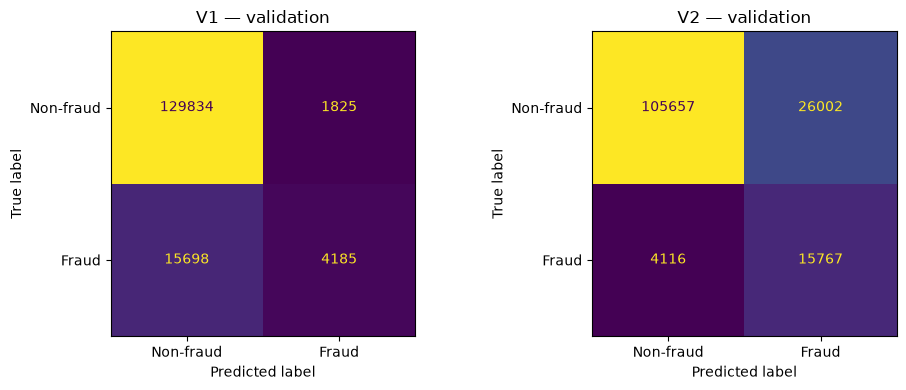

In [6]:
display(metrics_table("validation").loc[keys].round(4))

def plot_confusion_matrices(split):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, version in zip(axes, VERSIONS):
        m = reports[split, version]["metrics"]
        matrix = np.array([[m["true_negatives"], m["false_positives"]],
                           [m["false_negatives"], m["true_positives"]]])
        ConfusionMatrixDisplay(matrix, display_labels=["Non-fraud", "Fraud"]).plot(
            ax=ax, colorbar=False, values_format="d")
        ax.set_title(f"{version.upper()} — {split}")
    fig.tight_layout()
    plt.show()

plot_confusion_matrices("validation")

## 8. Final held-out evaluation
The two fixed configurations are refitted on the full development period (12 November 2022–3 April 2023, 758,025 orders). The held-out evaluation period contains 191,847 orders from 4 April to 11 May 2023. The following tables and plots use the final evaluation reports, not validation metrics.

,V1,V2
accuracy,0.8820,0.7743
fraud_precision,0.5651,0.3273
fraud_recall,0.2564,0.7579
fraud_f1,0.3528,0.4571
average_precision,0.4362,0.4376
roc_auc,0.8186,0.8207
true_negatives,163046.0000,130316.0000
false_positives,4746.0000,37476.0000
false_negatives,17887.0000,5824.0000
true_positives,6168.0000,18231.0000


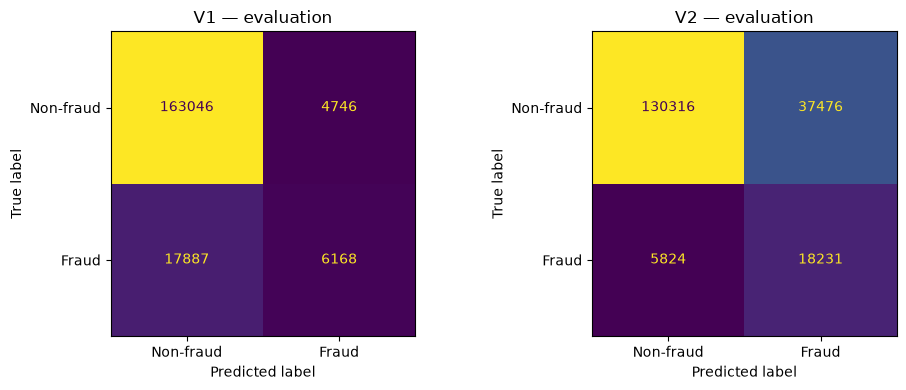

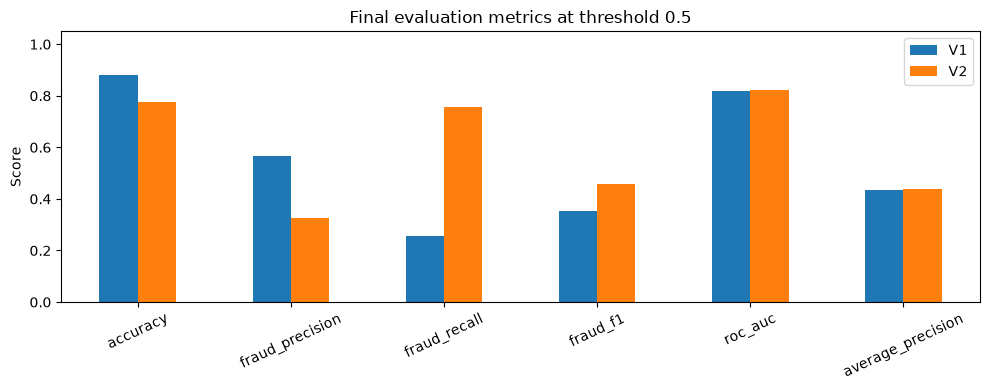

In [7]:
final = metrics_table("evaluation")
display(final.loc[keys].round(4))
plot_confusion_matrices("evaluation")
metric_names = ["accuracy", "fraud_precision", "fraud_recall", "fraud_f1", "roc_auc", "average_precision"]
ax = final.loc[metric_names].plot.bar(figsize=(10, 4), rot=25, ylim=(0, 1.05),
                                     title="Final evaluation metrics at threshold 0.5")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

## 9. ROC and precision–recall curves
Load the locally saved evaluation pipelines to generate scores on the actual held-out orders. Only load trusted model files produced by this project. Average precision summarises the precision–recall curve and is useful for imbalanced fraud data. ROC-AUC measures ranking across thresholds. Neither metric is tied to the 0.5 review threshold.

Saved models reproduce the final evaluation metrics.


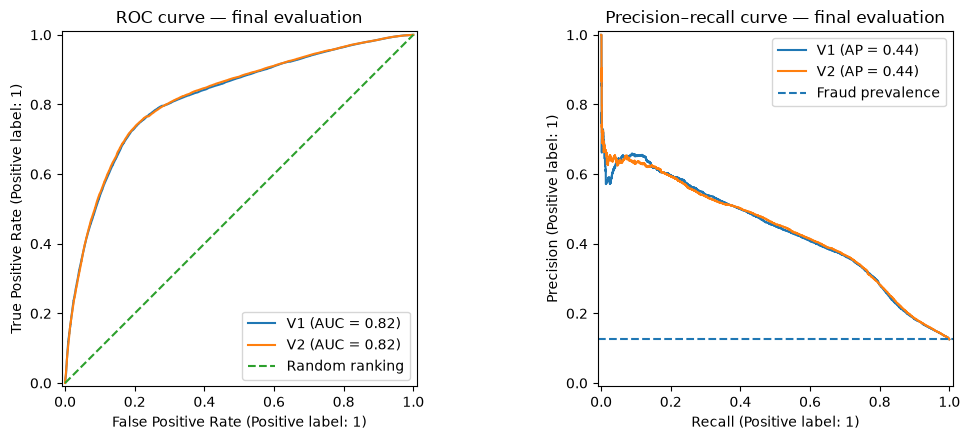

In [8]:
models = {}
scores = {}
X_eval, y_eval = X.loc[evaluation], y.loc[evaluation]
for version in VERSIONS:
    model_path = REPORT_DIR / f"evaluation-{version}.joblib"
    models[version] = load(model_path)
    scores[version] = models[version].predict_proba(X_eval)[:, 1]
    computed = decision_metrics(y_eval, scores[version], THRESHOLD)
    for key, value in computed.items():
        assert np.isclose(value, reports["evaluation", version]["metrics"][key]), (version, key)
    assert np.isclose(roc_auc_score(y_eval, scores[version]), reports["evaluation", version]["metrics"]["roc_auc"])
print("Saved models reproduce the final evaluation metrics.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for version in VERSIONS:
    RocCurveDisplay.from_predictions(y_eval, scores[version], name=version.upper(), ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_eval, scores[version], name=version.upper(), ax=axes[1])
axes[0].plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
axes[1].axhline(y_eval.mean(), linestyle="--", label="Fraud prevalence")
axes[0].set_title("ROC curve — final evaluation")
axes[1].set_title("Precision–recall curve — final evaluation")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

## 10. Feature importance
The following plot uses the fitted V2 classifier's gain-based feature importance, including encoded categorical features. These values show which transformed predictors contribute to splits in the model; they do not prove causation or the direction of fraud risk.

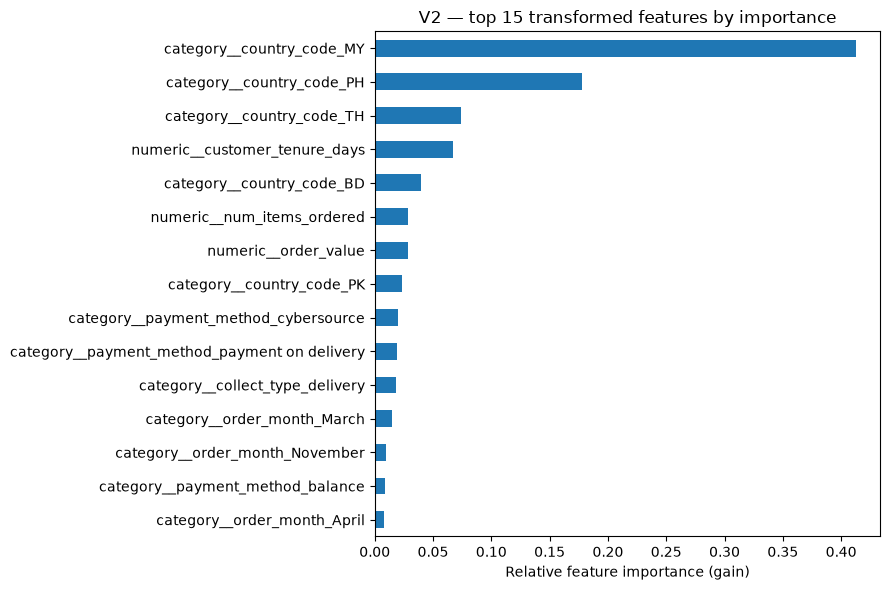

In [9]:
pipeline = models["v2"]
preprocessor = pipeline.named_steps["preprocessor"]
classifier = pipeline.named_steps["classifier"]
feature_names = preprocessor.get_feature_names_out()
importance = pd.Series(classifier.feature_importances_, index=feature_names)
ax = importance.nlargest(15).sort_values().plot.barh(figsize=(9, 6), title="V2 — top 15 transformed features by importance")
ax.set_xlabel("Relative feature importance (gain)")
plt.tight_layout()
plt.show()

## 11. Business interpretation
The original final evaluation shows V2 detects 18,231 fraud cases compared with V1's 6,168. Missed fraud falls from 17,887 to 5,824 (approximately 67.4% fewer). Recall improves from 25.64% to 75.79%, and F1 improves from 35.28% to 45.71%.

The trade-off is substantial: false alarms increase from 4,746 to 37,476, and precision declines from 56.51% to 32.73%. V2 flags 55,707 orders rather than 10,914. This may exceed investigation capacity. The final ROC-AUC and average precision are similar for both models, suggesting only a small ranking improvement. V2 is the preferred recall-focused candidate, not necessarily the overall champion. The team should consider its review capacity and the relative costs of missed fraud and false alarms when comparing candidates.

In [10]:
business = []
for version in VERSIONS:
    m = reports["evaluation", version]["metrics"]
    flagged = m["true_positives"] + m["false_positives"]
    business.append({"version": version.upper(), "flagged_orders": flagged,
                     "review_rate": flagged / len(evaluation),
                     "fraud_detected": m["true_positives"],
                     "fraud_missed": m["false_negatives"],
                     "false_alarms": m["false_positives"]})
display(pd.DataFrame(business))

,version,flagged_orders,review_rate,fraud_detected,fraud_missed,false_alarms
0,V1,10914,0.056889,6168,17887,4746
1,V2,55707,0.290372,18231,5824,37476


## 12. MLflow evidence and runtime
Both final models were logged to the shared `Group2_SPBuy_Fraud_Detection` experiment. The original runs were `isabelle-xgboost-v1-evaluation` and `isabelle-xgboost-v2-evaluation`. Both were reported FINISHED and successfully downloaded as complete scikit-learn pipelines. The recorded model logging duration includes packaging and transfer rather than pure network upload time. Local compressed model size is not the full size of the MLflow model package.

In [11]:
timing = ["preparation_seconds", "fit_seconds", "evaluation_seconds",
          "model_logging_seconds", "mlflow_logging_seconds", "model_size_mb"]
display(final.reindex(timing).round(4))
for version in VERSIONS:
    evidence = reports["evaluation", version].get("mlflow", {})
    print(version.upper(), "run ID:", evidence.get("run_id", "Not present in local report"))
    print("Model URI:", evidence.get("model_uri", "Not present in local report"))

,V1,V2
preparation_seconds,35.710,27.900
fit_seconds,5.230,4.960
evaluation_seconds,0.600,0.640
model_logging_seconds,18.460,16.610
mlflow_logging_seconds,20.520,18.430
model_size_mb,0.046,0.046


V1 run ID: b3848589bc0d4aaca3c8f7a7e145bab8
Model URI: models:/m-fe5db3dea8fa473687fd899f2181a66b
V2 run ID: 4f24a8b840b04467983cc9fa3837c7f2
Model URI: models:/m-6276eac4ad2d4f6e8db518f89fa10388


### 12.1 Optional live MLflow prediction verification
Set `VERIFY_REMOTE = True` when the AWS Learner Lab is running and your trusted project MLflow server is reachable. This downloads both trusted remote models, verifies the run status and compares their predictions with the local pipelines on the same 100 held-out rows. No new runs are created and no customer records are uploaded.

In [14]:
VERIFY_REMOTE = True  # Change to True for the live verification.
if VERIFY_REMOTE:
    import mlflow
    import mlflow.sklearn
    from config import configure_mlflow
    import os

    os.environ["MLFLOW_TRACKING_URI"] = (
    "http://group2-mlflow-isabelle.us-east-1.elasticbeanstalk.com"
)

    configure_mlflow()
    
    sample = X_eval.iloc[:100]
    for version in VERSIONS:
        evidence = reports["evaluation", version]["mlflow"]
        run = mlflow.get_run(evidence["run_id"])
        assert run.info.status == "FINISHED"
        remote = mlflow.sklearn.load_model(evidence["model_uri"])
        local_scores = models[version].predict_proba(sample)[:, 1]
        remote_scores = remote.predict_proba(sample)[:, 1]
        np.testing.assert_allclose(remote_scores, local_scores, rtol=1e-6, atol=1e-7)
        np.testing.assert_array_equal(remote_scores >= THRESHOLD, local_scores >= THRESHOLD)
        print(f"{version.upper()}: remote model predictions match local model ({len(sample)} orders).")
else:
    print("Live MLflow prediction verification skipped. Set VERIFY_REMOTE=True to run it.")

V1: remote model predictions match local model (100 orders).
V2: remote model predictions match local model (100 orders).


## 13. Conclusion and pipeline integration
Both XGBoost versions use shared feature preparation and an agreed evaluation procedure. The V2 class-weighting strategy improved recall and F1 at the fixed threshold while increasing false alarms. Both models train in approximately five seconds on the final training set in the original runs, and the local compressed pipelines are under 50 KiB each.

The reusable `train_xgboost(features, labels, version, n_jobs)` function accepts already prepared training rows so the group pipeline can avoid repeating historical data loading. The automated workflow must keep evaluation data separate, retrain using accepted historical and new labelled data, and log the resulting model artifacts. Full end-to-end timing and integration must still be verified with the group; standalone training speed does not establish that the complete pipeline meets the three-minute requirement.